# Q2: training data size

Party in Thee Code. Character TF-IDF + linear SVM, C=1. The settings and validation IDs stay fixed; only the number of labeled training examples changes.

In [1]:
import pandas as pd
from IPython.display import display, Image
from baseline import ROOT, load_data, load_split
from q2 import run_q2, nested_subsets

train, val = load_split(load_data(ROOT / "data" / "train.csv"))
subsets = nested_subsets(train)
display(pd.DataFrame([{
    "training_rows": n,
    "human": int((part.label == 0).sum()),
    "AI": int((part.label == 1).sum())
} for n, part in subsets.items()]))
print("Validation rows:", len(val))

Validation rows: 2000


,training_rows,human,AI
0,500,250,250
1,1000,500,500
2,2000,1000,1000
3,5000,2500,2500
4,8000,4000,4000


## Learning-curve runs

Every subset comes from the shared 8,000-row training partition. Subsets are balanced and nested with seed 42. Each run fits a new TF-IDF vectorizer on its own subset, then trains the same SVM configuration. AUROC uses SVM decision scores; these are not probabilities. The Q1 probability-calibration step is not used for this learning curve.

In [2]:
curve = run_q2(ROOT / "data" / "train.csv")
display(curve[["training_rows", "training_auroc", "validation_auroc", "generalization_gap"]])

n=500: train=1.000000, val=0.905811, fit=1.409s
n=1000: train=1.000000, val=0.926868, fit=2.185s
n=2000: train=1.000000, val=0.947813, fit=4.396s
n=5000: train=1.000000, val=0.964091, fit=11.539s
n=8000: train=0.999997, val=0.970704, fit=18.758s
 training_rows  training_auroc  validation_auroc  fit_time_seconds  vocabulary_size  human_training_rows  ai_training_rows  validation_rows  generalization_gap
           500        1.000000          0.905811          1.409209            50000                  250               250             2000            0.094189
          1000        1.000000          0.926868          2.184670            50000                  500               500             2000            0.073132
          2000        1.000000          0.947813          4.395773            50000                 1000              1000             2000            0.052187
          5000        1.000000          0.964091         11.538691            50000                 2500          

,training_rows,training_auroc,validation_auroc,generalization_gap
0,500,1.000000,0.905811,0.094189
1,1000,1.000000,0.926868,0.073132
2,2000,1.000000,0.947813,0.052187
3,5000,1.000000,0.964091,0.035909
4,8000,0.999997,0.970704,0.029293


## Figure

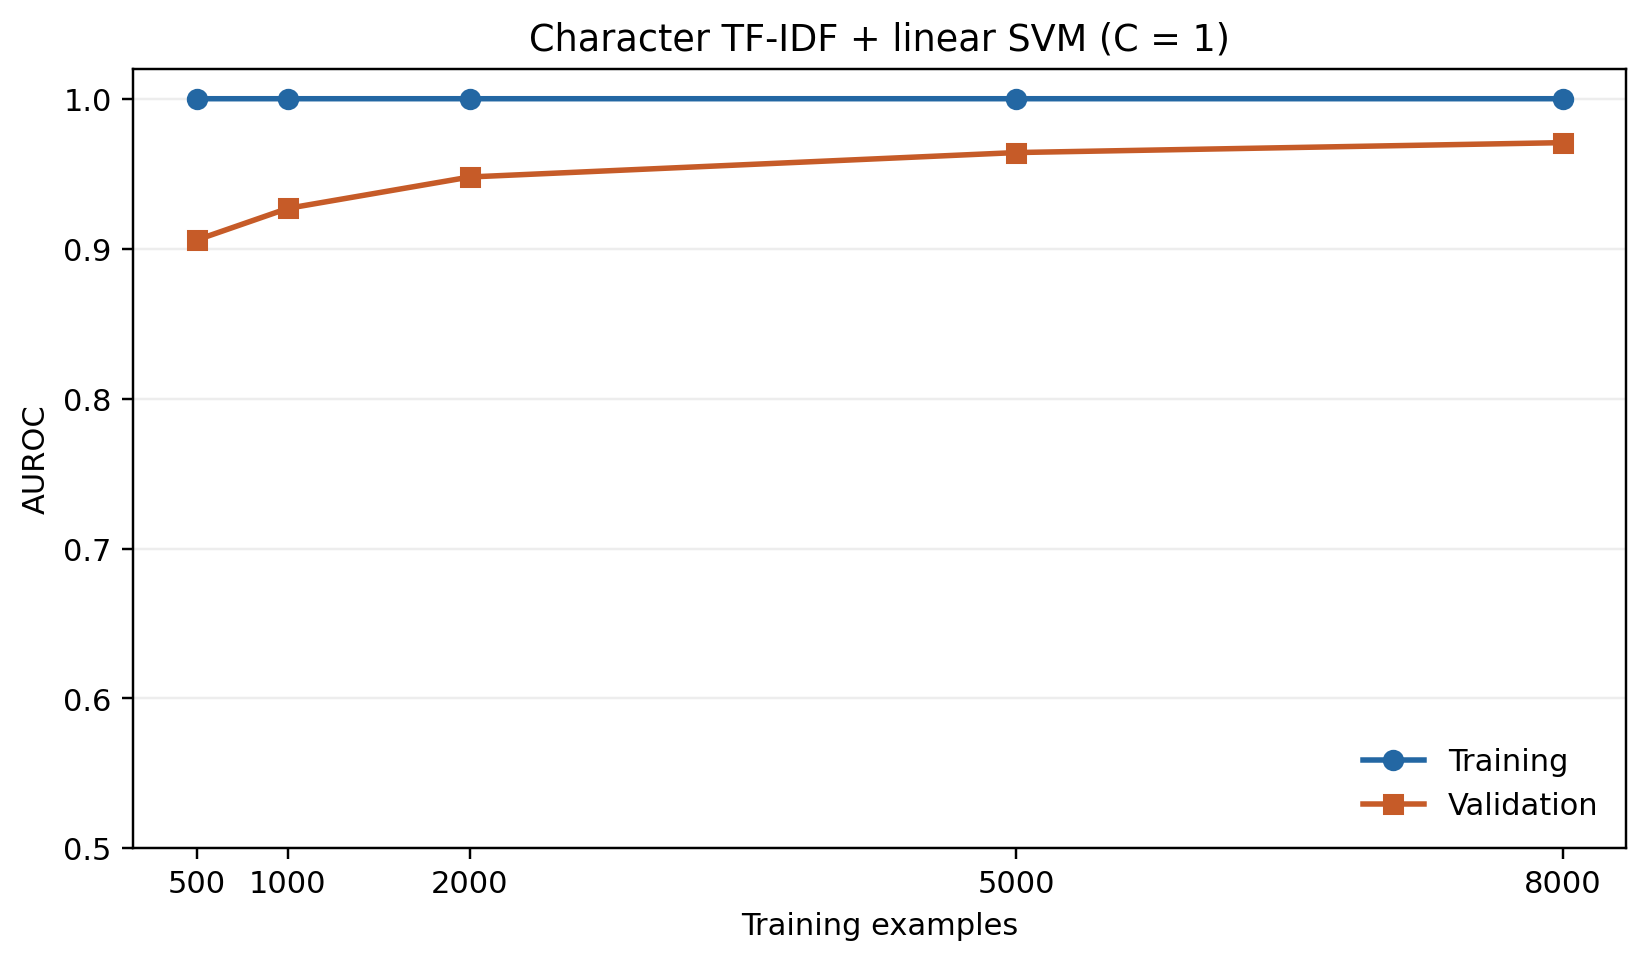

In [3]:
display(Image(filename=str(ROOT / "results" / "q2" / "q2_learning_curve.png")))

## Checks

In [4]:
assert curve.training_rows.tolist() == [500, 1000, 2000, 5000, 8000]
assert curve.validation_rows.eq(2000).all()
assert set(subsets[500].id).issubset(set(subsets[1000].id))
assert not set(train.id).intersection(set(val.id))
q1_svm = pd.read_csv(ROOT / "results" / "q1" / "model_comparison.csv").query("family == 'char_svm'").iloc[0]
assert abs(curve.iloc[-1].validation_auroc - q1_svm.validation_auroc) < 1e-10
print("Shared split unchanged. The 8,000-row AUROC matches Q1.")

Shared split unchanged. The 8,000-row AUROC matches Q1.


Outputs are under results/q2/. The subset ID files make the samples reproducible. This is one nested sampling run, so small changes in the curve should not be treated as certain trends across all possible samples.